In [ ]:
!nvidia-smi
!pip install -q timm wandb albumentations

Sat Nov  7 21:29:03 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P0             30W /   70W |     105MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!cp /content/drive/MyDrive/retinopatia/aptos_384.zip /content/
!unzip -q -o /content/aptos_384.zip -d /content/data
!ls /content/data/aptos_384/imagenes | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
3583


In [ ]:
import random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Parámetros
SEMILLA = 42
IMG = 384
BATCH = 16
NUM_CLASES = 5
NOMBRES = {0: "Sin RD", 1: "Leve", 2: "Moderada", 3: "Severa", 4: "Proliferativa"}
ORDEN = list(NOMBRES.values())

# Rutas
DATOS = Path("/content/data/aptos_384")
IMAGENES = DATOS / "imagenes"
DRIVE = Path("/content/drive/MyDrive/retinopatia")
CHECKPOINTS = DRIVE / "checkpoints"
RESULTADOS = DRIVE / "resultados"
for carpeta in (CHECKPOINTS, RESULTADOS):
    carpeta.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)

fijar_semilla(SEMILLA)

# Partición
df = pd.read_csv(DRIVE / "particion.csv")
df["path"] = df["id_code"].map(lambda x: str(IMAGENES / f"{x}.png"))
assert all(Path(p).exists() for p in df["path"]), "Faltan imágenes"
print(df["particion"].value_counts())

Dispositivo: cuda
particion
train    2507
val       542
test      534
Name: count, dtype: int64


In [ ]:
import wandb
from google.colab import userdata

wandb.login(key=userdata.get("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


True

In [ ]:
def normalizar_color(img_rgb, sigma_rel=30, umbral=10, erosion=3):
    tam = img_rgb.shape[0]
    sigma = tam / sigma_rel
    img = img_rgb.astype(np.float32)

    # 1. Máscara del ojo según el contenido real de la imagen
    gris = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    mascara = (gris > umbral).astype(np.float32)
    nucleo = np.ones((2 * erosion + 1, 2 * erosion + 1), np.uint8)
    mascara = cv2.erode(mascara, nucleo)

    # 2. Desenfoque solo con píxeles del ojo (convolución normalizada)
    suma = cv2.GaussianBlur(img * mascara[:, :, None], (0, 0), sigma)
    peso = cv2.GaussianBlur(mascara, (0, 0), sigma)[:, :, None]
    desenfoque = suma / np.maximum(peso, 1e-3)

    # 3. Quitar la iluminación, amplificar el detalle y limpiar el fondo
    salida = 4 * img - 4 * desenfoque + 128
    salida = np.clip(salida, 0, 255) * mascara[:, :, None]
    return salida.astype(np.uint8)

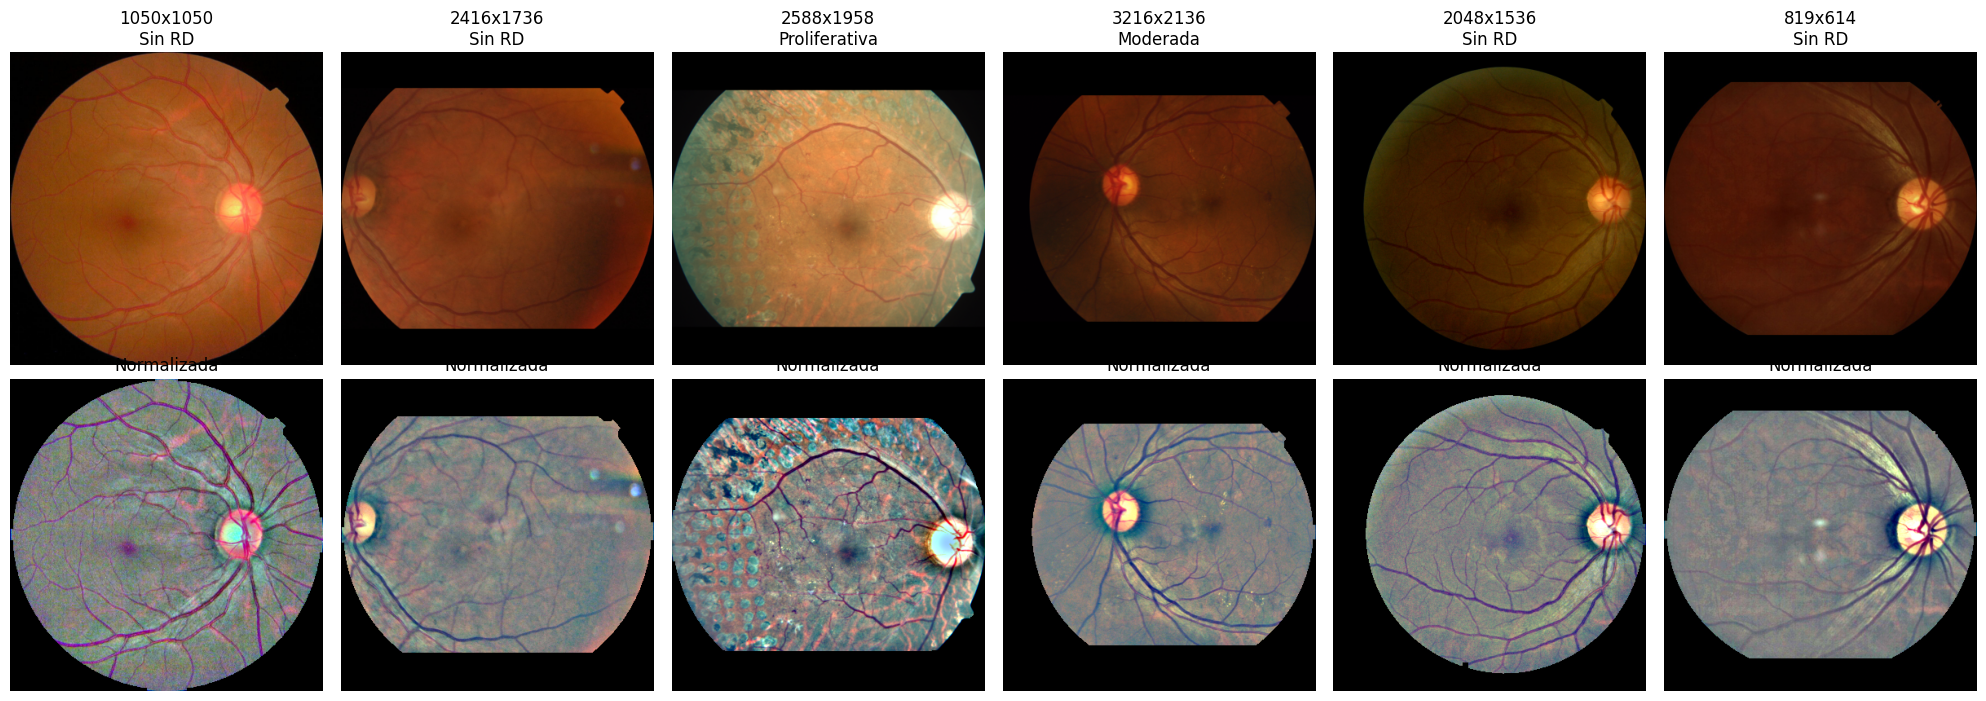

In [ ]:
top = df["tamano"].value_counts().head(6).index
fig, axes = plt.subplots(2, 6, figsize=(20, 7))

for i, t in enumerate(top):
    f = df[df["tamano"] == t].sample(1, random_state=SEMILLA).iloc[0]
    img = cv2.cvtColor(cv2.imread(f["path"]), cv2.COLOR_BGR2RGB)
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"{t}\n{f['clase']}")
    axes[1, i].imshow(normalizar_color(img))
    axes[1, i].set_title("Normalizada")

for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTADOS / "normalizacion_color.png", dpi=150)
plt.show()

In [ ]:
MEDIA = (0.485, 0.456, 0.406)
DESV = (0.229, 0.224, 0.225)

tf_train = A.Compose([
    A.Resize(IMG, IMG),
    A.Rotate(limit=180, border_mode=cv2.BORDER_CONSTANT, p=0.8),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.Normalize(mean=MEDIA, std=DESV),
    ToTensorV2(),
])

tf_eval = A.Compose([
    A.Resize(IMG, IMG),
    A.Normalize(mean=MEDIA, std=DESV),
    ToTensorV2(),
])

In [ ]:
class RetinaDataset(Dataset):
    def __init__(self, df, transform):
        self.rutas = df["path"].tolist()
        self.etiquetas = df["diagnosis"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.rutas[i]), cv2.COLOR_BGR2RGB)
        img = normalizar_color(img)
        img = self.transform(image=img)["image"]
        return img, self.etiquetas[i]


def crear_loaders(df_train, df_val, sobremuestreo=True):
    ds_train = RetinaDataset(df_train, tf_train)
    ds_val = RetinaDataset(df_val, tf_eval)

    if sobremuestreo:
        conteo = df_train["diagnosis"].value_counts()
        pesos = df_train["diagnosis"].map(1.0 / conteo).values
        sampler = WeightedRandomSampler(
            torch.as_tensor(pesos, dtype=torch.double),
            num_samples=len(df_train),
            replacement=True,
        )
        dl_train = DataLoader(ds_train, batch_size=BATCH, sampler=sampler,
                              num_workers=2, pin_memory=True, drop_last=True)
    else:
        dl_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True,
                              num_workers=2, pin_memory=True, drop_last=True)

    dl_val = DataLoader(ds_val, batch_size=BATCH * 2, shuffle=False,
                        num_workers=2, pin_memory=True)
    return dl_train, dl_val

Clases en una época con sobremuestreo:
Sin RD           236
Leve             247
Moderada         252
Severa           271
Proliferativa    247
Name: count, dtype: int64

Forma del lote: (16, 3, 384, 384)


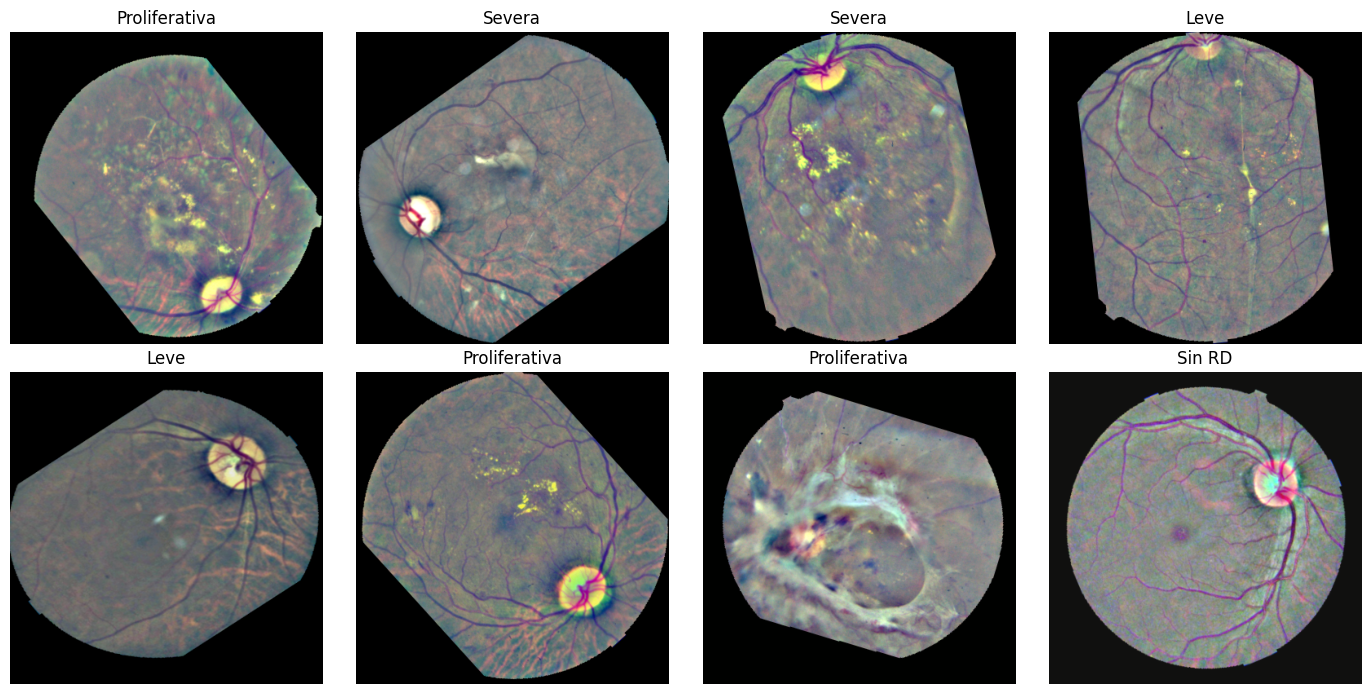

In [ ]:
fold = 0
f_train = df[(df["particion"] == "train") & (df["fold"] != fold)]
f_val = df[(df["particion"] == "train") & (df["fold"] == fold)]
dl_train, dl_val = crear_loaders(f_train, f_val)

# Balance real del sampler en una época
indices = list(dl_train.sampler)
print("Clases en una época con sobremuestreo:")
print(pd.Series(f_train["diagnosis"].values[indices]).map(NOMBRES).value_counts().reindex(ORDEN))

# Un lote de ejemplo
imgs, etiquetas = next(iter(dl_train))
print("\nForma del lote:", tuple(imgs.shape))

media = torch.tensor(MEDIA).view(3, 1, 1)
desv = torch.tensor(DESV).view(3, 1, 1)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img, y in zip(axes.flat, imgs[:8], etiquetas[:8]):
    ax.imshow((img * desv + media).permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(NOMBRES[int(y)])
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTADOS / "lote_aumentado.png", dpi=150)
plt.show()

In [ ]:
import time
import timm
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Hiperparámetros del entrenamiento
EPOCAS = 20
EPOCAS_CABEZA = 2
LR_CABEZA = 1e-3
LR = 3e-4
WD = 1e-2
PROYECTO_WANDB = "retinopatia-aptos"


def crear_modelo(arquitectura):
    modelo = timm.create_model(arquitectura, pretrained=True, num_classes=NUM_CLASES)
    return modelo.to(DEVICE)


def congelar_cuerpo(modelo, congelar):
    for p in modelo.parameters():
        p.requires_grad = not congelar
    for p in modelo.get_classifier().parameters():
        p.requires_grad = True


def crear_optimizador(modelo, fase, epocas):
    if fase == "cabeza":
        congelar_cuerpo(modelo, True)
        opt = torch.optim.AdamW(modelo.get_classifier().parameters(),
                                lr=LR_CABEZA, weight_decay=WD)
        return opt, None

    congelar_cuerpo(modelo, False)
    opt = torch.optim.AdamW(modelo.parameters(), lr=LR, weight_decay=WD)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=epocas - EPOCAS_CABEZA, eta_min=1e-6
    )
    return opt, scheduler

In [ ]:
def entrenar_epoca(modelo, loader, optimizador, scaler, criterio):
    modelo.train()
    perdida_total, aciertos, n = 0.0, 0, 0

    for imgs, y in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        optimizador.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda"):
            salida = modelo(imgs)
            perdida = criterio(salida, y)

        scaler.scale(perdida).backward()
        scaler.step(optimizador)
        scaler.update()

        perdida_total += perdida.item() * len(y)
        aciertos += (salida.argmax(1) == y).sum().item()
        n += len(y)

    return perdida_total / n, aciertos / n


@torch.no_grad()
def evaluar(modelo, loader, criterio):
    modelo.eval()
    perdida_total, n = 0.0, 0
    todas_y, todas_prob = [], []

    for imgs, y in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        with torch.amp.autocast("cuda"):
            salida = modelo(imgs)
            perdida = criterio(salida, y)

        perdida_total += perdida.item() * len(y)
        n += len(y)
        todas_y.append(y.cpu())
        todas_prob.append(salida.float().softmax(1).cpu())

    return perdida_total / n, torch.cat(todas_y).numpy(), torch.cat(todas_prob).numpy()

In [ ]:
def ejecutar(arquitectura, df_tr, df_va, nombre, epocas=EPOCAS):
    ruta_ck = CHECKPOINTS / f"{nombre}_ultimo.pt"
    fijar_semilla(SEMILLA)
    modelo = crear_modelo(arquitectura)
    criterio = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler("cuda")
    inicio, historial = 0, []

    # Reanudar si existe un checkpoint
    if ruta_ck.exists():
        ck = torch.load(ruta_ck, map_location=DEVICE, weights_only=False)
        inicio, historial = ck["epoca"] + 1, ck["historial"]
        if inicio >= epocas:
            print(f"{nombre}: ya estaba completo")
            return historial
        modelo.load_state_dict(ck["modelo"])
        fase = "cabeza" if inicio < EPOCAS_CABEZA else "completa"
        optimizador, scheduler = crear_optimizador(modelo, fase, epocas)
        if ck["fase"] == fase:
            optimizador.load_state_dict(ck["optimizador"])
            if scheduler is not None:
                scheduler.load_state_dict(ck["scheduler"])
        scaler.load_state_dict(ck["scaler"])
        print(f"{nombre}: reanudando desde la época {inicio + 1}")
    else:
        fase = "cabeza" if EPOCAS_CABEZA > 0 else "completa"
        optimizador, scheduler = crear_optimizador(modelo, fase, epocas)

    dl_train, dl_val = crear_loaders(df_tr, df_va)
    run = wandb.init(
        project=PROYECTO_WANDB, name=nombre, id=nombre, resume="allow",
        config={"arquitectura": arquitectura, "epocas": epocas, "img": IMG,
                "batch": BATCH, "lr": LR, "lr_cabeza": LR_CABEZA, "wd": WD,
                "epocas_cabeza": EPOCAS_CABEZA, "n_train": len(df_tr), "n_val": len(df_va)},
    )

    for epoca in range(inicio, epocas):
        if fase == "cabeza" and epoca >= EPOCAS_CABEZA:
            fase = "completa"
            optimizador, scheduler = crear_optimizador(modelo, fase, epocas)

        t0 = time.time()
        lr_actual = optimizador.param_groups[0]["lr"]
        perd_tr, exac_tr = entrenar_epoca(modelo, dl_train, optimizador, scaler, criterio)
        perd_va, y_true, y_prob = evaluar(modelo, dl_val, criterio)
        y_pred = y_prob.argmax(1)
        if scheduler is not None:
            scheduler.step()

        m = {
            "epoca": epoca + 1, "fase": fase, "lr": lr_actual,
            "perdida_train": perd_tr, "exactitud_train": exac_tr,
            "perdida_val": perd_va,
            "exactitud_val": accuracy_score(y_true, y_pred),
            "f1_macro_val": f1_score(y_true, y_pred, average="macro"),
            "qwk_val": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
            "segundos": time.time() - t0,
        }
        historial.append(m)
        wandb.log(m, step=epoca + 1)

        torch.save({
            "modelo": modelo.state_dict(),
            "optimizador": optimizador.state_dict(),
            "scheduler": scheduler.state_dict() if scheduler else None,
            "scaler": scaler.state_dict(),
            "epoca": epoca, "fase": fase, "historial": historial,
        }, ruta_ck)

        print(f"{nombre} | época {epoca + 1:2d}/{epocas} | {fase:8s} | "
              f"pérdida {perd_tr:.3f}/{perd_va:.3f} | exactitud val {m['exactitud_val']:.3f} | "
              f"F1 {m['f1_macro_val']:.3f} | {m['segundos']:.0f}s")

    torch.save(modelo.state_dict(), CHECKPOINTS / f"{nombre}_pesos.pt")
    pd.DataFrame(historial).to_csv(RESULTADOS / f"historial_{nombre}.csv", index=False)
    run.finish()
    return historial

In [ ]:
sub_tr = f_train.groupby("diagnosis").head(40)
sub_va = f_val.groupby("diagnosis").head(20)

for arq in ["efficientnet_b0", "resnet50"]:
    torch.cuda.reset_peak_memory_stats()
    ejecutar(arq, sub_tr, sub_va, nombre=f"prueba_{arq}", epocas=3)
    print(f"Memoria máxima de GPU con {arq}: "
          f"{torch.cuda.max_memory_allocated() / 1e9:.1f} GB de 15 GB\n")

for p in CHECKPOINTS.glob("prueba_*"):
    p.unlink()
for p in RESULTADOS.glob("historial_prueba_*"):
    p.unlink()

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

prueba_efficientnet_b0 | época  1/3 | cabeza   | pérdida 2.629/3.236 | exactitud val 0.180 | F1 0.158 | 16s
prueba_efficientnet_b0 | época  2/3 | cabeza   | pérdida 2.240/2.869 | exactitud val 0.190 | F1 0.179 | 14s
prueba_efficientnet_b0 | época  3/3 | completa | pérdida 1.897/3.600 | exactitud val 0.430 | F1 0.360 | 13s


epoca,▁▅█
exactitud_train,▁▃█
exactitud_val,▁▁█
f1_macro_val,▁▂█
lr,██▁
perdida_train,█▄▁
perdida_val,▅▁█
qwk_val,▁▄█
segundos,█▃▁
epoca,3
exactitud_train,0.35417


Memoria máxima de GPU con efficientnet_b0: 2.2 GB de 15 GB



model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

prueba_resnet50 | época  1/3 | cabeza   | pérdida 1.605/1.605 | exactitud val 0.200 | F1 0.067 | 10s
prueba_resnet50 | época  2/3 | cabeza   | pérdida 1.613/1.588 | exactitud val 0.310 | F1 0.215 | 11s
prueba_resnet50 | época  3/3 | completa | pérdida 1.564/1.542 | exactitud val 0.240 | F1 0.136 | 8s


epoca,▁▅█
exactitud_train,▁▄█
exactitud_val,▁█▄
f1_macro_val,▁█▄
lr,██▁
perdida_train,▇█▁
perdida_val,█▆▁
qwk_val,▁█▄
segundos,▆█▁
epoca,3
exactitud_train,0.28646


Memoria máxima de GPU con resnet50: 2.5 GB de 15 GB



In [ ]:
resumen = []
for arq in ["efficientnet_b0", "resnet50"]:
    for fold in [0, 1]:
        f_tr = df[(df["particion"] == "train") & (df["fold"] != fold)]
        f_va = df[(df["particion"] == "train") & (df["fold"] == fold)]
        hist = ejecutar(arq, f_tr, f_va, nombre=f"{arq}_fold{fold}")

        ultima = hist[-1]
        mejor = max(hist, key=lambda h: h["exactitud_val"])
        resumen.append({
            "arquitectura": arq, "fold": fold,
            "exactitud": ultima["exactitud_val"],
            "f1_macro": ultima["f1_macro_val"],
            "qwk": ultima["qwk_val"],
            "mejor_epoca": mejor["epoca"],
        })

cv = pd.DataFrame(resumen)
cv.to_csv(RESULTADOS / "cv_resultados.csv", index=False)
cv

efficientnet_b0_fold0 | época  1/20 | cabeza   | pérdida 2.178/2.406 | exactitud val 0.231 | F1 0.203 | 76s
efficientnet_b0_fold0 | época  2/20 | cabeza   | pérdida 1.695/1.779 | exactitud val 0.393 | F1 0.316 | 70s
efficientnet_b0_fold0 | época  3/20 | completa | pérdida 1.229/0.834 | exactitud val 0.758 | F1 0.584 | 71s
efficientnet_b0_fold0 | época  4/20 | completa | pérdida 0.667/0.784 | exactitud val 0.778 | F1 0.591 | 71s
efficientnet_b0_fold0 | época  5/20 | completa | pérdida 0.481/0.897 | exactitud val 0.743 | F1 0.579 | 73s
efficientnet_b0_fold0 | época  6/20 | completa | pérdida 0.358/0.923 | exactitud val 0.762 | F1 0.614 | 70s
efficientnet_b0_fold0 | época  7/20 | completa | pérdida 0.271/0.858 | exactitud val 0.782 | F1 0.623 | 71s
efficientnet_b0_fold0 | época  8/20 | completa | pérdida 0.206/0.830 | exactitud val 0.808 | F1 0.625 | 75s
efficientnet_b0_fold0 | época  9/20 | completa | pérdida 0.167/0.895 | exactitud val 0.797 | F1 0.608 | 73s
efficientnet_b0_fold0 | époc

epoca,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
exactitud_train,▁▂▄▆▆▇▇▇▇▇██████████
exactitud_val,▁▃▇▇▇▇██████████████
f1_macro_val,▁▃▇▇▇▇██▇▇██████████
lr,██▃▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁
perdida_train,█▆▅▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
perdida_val,█▅▁▁▁▂▁▁▁▂▁▂▁▁▁▂▁▁▁▁
qwk_val,▁▃▇█▇███████████████
segundos,█▁▂▂▄▁▂▇▄▅▂▂▄▂▃▄▂▃▃▂
epoca,20
exactitud_train,0.99119


efficientnet_b0_fold1 | época  1/20 | cabeza   | pérdida 2.277/2.319 | exactitud val 0.259 | F1 0.224 | 69s
efficientnet_b0_fold1 | época  2/20 | cabeza   | pérdida 1.771/1.599 | exactitud val 0.439 | F1 0.339 | 68s
efficientnet_b0_fold1 | época  3/20 | completa | pérdida 1.248/0.984 | exactitud val 0.682 | F1 0.516 | 70s
efficientnet_b0_fold1 | época  4/20 | completa | pérdida 0.855/0.712 | exactitud val 0.761 | F1 0.573 | 71s
efficientnet_b0_fold1 | época  5/20 | completa | pérdida 0.610/0.705 | exactitud val 0.778 | F1 0.619 | 73s
efficientnet_b0_fold1 | época  6/20 | completa | pérdida 0.435/0.829 | exactitud val 0.743 | F1 0.569 | 71s
efficientnet_b0_fold1 | época  7/20 | completa | pérdida 0.291/0.688 | exactitud val 0.788 | F1 0.632 | 71s
efficientnet_b0_fold1 | época  8/20 | completa | pérdida 0.220/0.890 | exactitud val 0.761 | F1 0.598 | 72s
efficientnet_b0_fold1 | época  9/20 | completa | pérdida 0.207/0.801 | exactitud val 0.773 | F1 0.604 | 71s
efficientnet_b0_fold1 | époc

epoca,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
exactitud_train,▁▂▄▅▆▇▇▇▇███████████
exactitud_val,▁▃▆▇▇▇█▇▇███████████
f1_macro_val,▁▃▆▇▇▇█▇▇▇█▇██▇█████
lr,██▃▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁
perdida_train,█▆▅▄▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
perdida_val,█▅▂▁▁▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁
qwk_val,▁▃▇█████████████████
segundos,▃▁▄▅▇▅▅▆▄▄▆▅▅▇▅▅█▅▅█
epoca,20
exactitud_train,0.99199


resnet50_fold0 | época  1/20 | cabeza   | pérdida 1.533/1.412 | exactitud val 0.553 | F1 0.313 | 70s
resnet50_fold0 | época  2/20 | cabeza   | pérdida 1.407/1.171 | exactitud val 0.565 | F1 0.260 | 68s
resnet50_fold0 | época  3/20 | completa | pérdida 1.053/0.685 | exactitud val 0.707 | F1 0.543 | 72s
resnet50_fold0 | época  4/20 | completa | pérdida 0.866/0.614 | exactitud val 0.755 | F1 0.599 | 80s
resnet50_fold0 | época  5/20 | completa | pérdida 0.749/0.606 | exactitud val 0.736 | F1 0.575 | 78s
resnet50_fold0 | época  6/20 | completa | pérdida 0.599/0.616 | exactitud val 0.761 | F1 0.597 | 78s
resnet50_fold0 | época  7/20 | completa | pérdida 0.502/0.564 | exactitud val 0.791 | F1 0.614 | 79s
resnet50_fold0 | época  8/20 | completa | pérdida 0.455/0.584 | exactitud val 0.805 | F1 0.638 | 80s
resnet50_fold0 | época  9/20 | completa | pérdida 0.402/0.611 | exactitud val 0.783 | F1 0.622 | 79s
resnet50_fold0 | época 10/20 | completa | pérdida 0.317/0.636 | exactitud val 0.786 | F1 0.

epoca,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
exactitud_train,▁▂▄▄▅▆▆▇▇▇▇█▇▇██████
exactitud_val,▁▁▅▆▆▇▇█▇▇███▇██████
f1_macro_val,▂▁▆▇▇▇▇█▇▇███████▇█▇
lr,██▃▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁
perdida_train,█▇▆▅▄▃▃▃▂▂▂▁▂▁▁▁▁▁▁▁
perdida_val,█▆▂▁▁▁▁▁▁▂▁▁▁▂▁▁▂▂▂▂
qwk_val,▅▁▇██▇██████████████
segundos,▂▁▄█▇▇▇█▇▆▇█▇▇▆▇▇▇▆▇
epoca,20
exactitud_train,0.96074


resnet50_fold1 | época  1/20 | cabeza   | pérdida 1.550/1.345 | exactitud val 0.672 | F1 0.468 | 73s
resnet50_fold1 | época  2/20 | cabeza   | pérdida 1.382/1.181 | exactitud val 0.592 | F1 0.327 | 68s
resnet50_fold1 | época  3/20 | completa | pérdida 1.134/0.684 | exactitud val 0.721 | F1 0.563 | 73s
resnet50_fold1 | época  4/20 | completa | pérdida 0.875/0.616 | exactitud val 0.757 | F1 0.609 | 80s
resnet50_fold1 | época  5/20 | completa | pérdida 0.757/0.541 | exactitud val 0.787 | F1 0.634 | 78s
resnet50_fold1 | época  6/20 | completa | pérdida 0.677/0.520 | exactitud val 0.786 | F1 0.617 | 80s
resnet50_fold1 | época  7/20 | completa | pérdida 0.626/0.638 | exactitud val 0.721 | F1 0.566 | 81s
resnet50_fold1 | época  8/20 | completa | pérdida 0.500/0.526 | exactitud val 0.791 | F1 0.638 | 81s
resnet50_fold1 | época  9/20 | completa | pérdida 0.452/0.544 | exactitud val 0.798 | F1 0.642 | 82s
resnet50_fold1 | época 10/20 | completa | pérdida 0.395/0.545 | exactitud val 0.791 | F1 0.

epoca,▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▇▇▇██
exactitud_train,▁▃▄▅▅▆▆▆▇▇▇▇████████
exactitud_val,▃▁▅▆▇▇▅▇▇▇▇▇█▇██████
f1_macro_val,▄▁▆▇█▇▆██▇█▇████████
lr,██▃▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁▁▁
perdida_train,█▇▆▅▄▄▃▃▂▂▂▂▁▁▁▁▁▁▁▁
perdida_val,█▇▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁
qwk_val,▂▁▆▇▇▇▇▇▇▇██████████
segundos,▃▁▃▇▆▇█▇█▇▆▆▇▇▇▇▇▆▇█
epoca,20
exactitud_train,0.9359


,arquitectura,fold,exactitud,f1_macro,qwk,mejor_epoca
0,efficientnet_b0,0,0.819777,0.647075,0.884510,17
1,efficientnet_b0,1,0.820431,0.655944,0.878962,19
2,resnet50,0,0.805423,0.616260,0.880232,11
3,resnet50,1,0.822825,0.654096,0.887642,20


In [ ]:
tabla_cv = cv.groupby("arquitectura").agg(
    media=("exactitud", "mean"),
    desv=("exactitud", "std"),
    f1_macro=("f1_macro", "mean"),
    qwk=("qwk", "mean"),
    mejor_epoca=("mejor_epoca", "mean"),
)
tabla_cv["Exactitud"] = [f"{m:.2f} ± {d:.2f}" for m, d in zip(tabla_cv["media"], tabla_cv["desv"])]
tabla_cv.to_csv(RESULTADOS / "tabla_cv.csv")
tabla_cv[["Exactitud", "f1_macro", "qwk", "mejor_epoca"]]

,Exactitud,f1_macro,qwk,mejor_epoca
arquitectura,,,,
efficientnet_b0,0.82 ± 0.00,0.651510,0.881736,18.0
resnet50,0.81 ± 0.01,0.635178,0.883937,15.5


Entrenamiento final

In [27]:
ARQ_FINAL = "efficientnet_b0"

f_train_final = df[df["particion"] == "train"]
f_val_final = df[df["particion"] == "val"]
print("Entrenamiento:", len(f_train_final), "| Validación:", len(f_val_final))

hist_final = ejecutar(ARQ_FINAL, f_train_final, f_val_final,
                      nombre=f"{ARQ_FINAL}_final", epocas=EPOCAS)

Entrenamiento: 2507 | Validación: 542
efficientnet_b0_final: ya estaba completo
